# Домашнее задание. Занятие 11. Мидтерм, этап 1: от сырого файла к чистой таблице

**DataGroup. Курс AI Engineering. Неделя 6**

Это тетрадь вашего мидтерм-проекта. На этапе 1 (домашка занятия 11) вы заполняете разделы 0-9: выбираете датасет и доводите его до чистой таблицы с EDA. На этапе 2 (домашка занятия 12, сам мидтерм) продолжаете **эту же тетрадь**, разделы 10-16: признаки, утечка, baseline и README. Полное ТЗ с критериями и списком датасетов в файле `Midterm_TZ.md`.

**Как работать с тетрадью**

1. Откройте её в Google Colab: «Файл», затем «Загрузить блокнот». Сразу переименуйте в `project.ipynb`: под этим именем она будет лежать в репозитории.
2. **Первой запустите ячейку «Помощники»** ниже. Если перезапустили среду, запустите её снова.
3. Идите по разделам сверху вниз. В каждом разделе есть **«Что сделать»**, ссылка на часть тетради практики занятия 11, где это показано на отелях, пустые ячейки для кода и ячейка **«Вывод»**: её заполняете своими словами.
4. Каждое решение про данные записывайте в журнал: `log("шаг", "что решили", len(df))`.
5. В конце этапа запустите самопроверку (раздел 9), потом «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь должна пройти без ошибок.
6. Загрузите тетрадь и файлы в публичный репозиторий на GitHub и сдайте **ссылку на репозиторий** в LMS. Как загрузить, в разделе 9 и в ТЗ.

**Баллы этапа 1: 100.**

| раздел | баллы |
|---|---|
| 0-1. Карточка проекта и первый взгляд | 10 |
| 2-3. Дубли и невозможные значения | 15 |
| 4. Пропуски | 20 |
| 5-6. Типы, даты и выбросы | 15 |
| 7. EDA: 5 графиков с выводами | 20 |
| 8. Функция `clean`, сторожа, журнал, чистый CSV | 10 |
| 9. Репозиторий: публичный, тетрадь с выводами | 10 |

**Данные.** Один датасет из списка в ТЗ или свой, согласованный в чате группы. Вот список коротко, ссылки и подробности в ТЗ:

| датасет | задача | уровень |
|---|---|---|
| клиенты телеком-компании (Telco) | классификация: уйдёт ли клиент | базовый |
| поездки на такси в Нью-Йорке | регрессия: чаевые или стоимость | базовый |
| рейтинги шоколада | регрессия: оценка плитки | базовый |
| банк: телемаркетинг вкладов | классификация: откроет ли вклад | средний |
| восхождения в Гималаях | классификация: дойдёт ли до вершины | средний |
| Airbnb в Нью-Йорке | регрессия: цена ночи | средний |
| песни Spotify | регрессия: популярность трека | средний |
| мебель IKEA | регрессия: цена | средний |
| оценки кофе | регрессия: итоговая оценка | продвинутый |
| дома в Эймсе | регрессия: цена дома | продвинутый |

**Как устроено.** Проверки с баллами здесь нет: работу проверяет преподаватель по критериям из ТЗ. Решения принимаете вы, и главное в каждом разделе не код, а **вывод**: что вы увидели и почему решили именно так. Короткий честный вывод лучше длинного пересказа кода.

**Чем пользоваться.** Помощники ниже: `load_csv`, `passport`, `log` и `show_journal`, `target_plot`, `selfcheck`. Всё остальное из тетради практики занятия 11: её функции можно копировать и менять под свои данные.

**Если застряли.** Каждый раздел ссылается на часть тетради практики, где то же самое сделано на отелях. Задайте вопрос в чате группы, не дожидаясь срока. И ставьте `print` после каждого шага: почти всегда окажется, что в таблице лежит не то, что вы думали.

---
## Помощники

Запустите эту ячейку первой. Она подключает библиотеки и создаёт пять функций для проекта.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("project_data")
DATA.mkdir(exist_ok=True)
TEAL, ORANGE, RED, NAVY, GRAY = "#278071", "#E0843B", "#B0413E", "#13293E", "#8A94A0"
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)


def load_csv(url, name="raw", **options):
    """Скачать CSV по ссылке один раз в папку project_data, дальше читать с диска."""
    path = DATA / f"{name}.csv"
    if not path.exists():
        urlretrieve(url, path)
    return pd.read_csv(path, **options)


def passport(table):
    """Паспорт данных: одна строка на столбец, тип, пропуски, разных значений, пример."""
    return pd.DataFrame({
        "тип": table.dtypes.astype(str),
        "пропусков": table.isna().sum(),
        "доля, %": (table.isna().mean() * 100).round(1),
        "разных": table.nunique(),
        "пример": table.iloc[0],
    })


journal = {}


def log(step, decision, rows):
    """Записать решение в журнал. Повторный запуск с тем же шагом перезаписывает запись."""
    journal[step] = {"решение": decision, "строк": rows}


def show_journal():
    """Журнал решений таблицей."""
    return pd.DataFrame(journal).T


def target_plot(table, groups, target, title, xlabel):
    """Цель по группам. Цель 0 и 1: доля единиц в процентах. Цель число: медиана."""
    is_class = set(table[target].dropna().unique()) <= {0, 1}
    stat = "mean" if is_class else "median"
    result = table.groupby(groups, observed=True)[target].agg([stat, "size"])
    values = result[stat] * 100 if is_class else result[stat]
    overall = table[target].mean() * 100 if is_class else table[target].median()
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    bars = ax.bar(result.index.astype(str), values, color=TEAL)
    ax.axhline(overall, color=ORANGE, ls="--", label="по всем данным")
    labels = ax.bar_label(bars, fmt="%.0f%%" if is_class else "%.1f", padding=2)
    for label in labels:
        label.set_bbox({"facecolor": "white", "edgecolor": "none", "pad": 1})
    ax.set_ylim(0, max(values.max(), overall) * 1.4)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(f"доля {target} = 1, %" if is_class else f"медиана {target}")
    ax.legend(loc="best")
    if len(result) > 6 or max(len(str(i)) for i in result.index) > 12:
        plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()
    return result.round(3)


def selfcheck(raw_table, clean_table, target):
    """Самопроверка этапа 1: что готово, а что нет."""
    has_target = target in clean_table.columns
    checks = [
        ("цель есть в чистой таблице", has_target),
        ("цель без пропусков", has_target and bool(clean_table[target].notna().all())),
        ("цель числом: класс 0 и 1 или число", has_target and pd.api.types.is_numeric_dtype(clean_table[target])),
        ("в чистой таблице нет пропусков", int(clean_table.isna().sum().sum()) == 0),
        ("полных дублей нет (если есть, объясните в выводе)", not clean_table.duplicated().any()),
        ("осталось больше половины строк", len(clean_table) > len(raw_table) / 2),
        ("в журнале минимум 5 решений", len(journal) >= 5),
    ]
    for name, ok in checks:
        print(("OK   " if ok else "НЕТ  ") + name)
    print(f"строк: было {len(raw_table)}, стало {len(clean_table)}; столбцов: было {raw_table.shape[1]}, стало {clean_table.shape[1]}")


print("помощники готовы")

помощники готовы


---
# Этап 1. Домашка занятия 11

---
## 0. Карточка проекта  ·  вместе с разделом 1: 10 баллов

**Что сделать.** Заполните таблицу ниже (двойной щелчок по ячейке) и укажите ссылку и цель в коде. Пример карточки: часть 1 тетради практики, раздел 1.1.

| вопрос | ответ |
|---|---|
| датасет и ссылка на источник | ... |
| что значит одна строка | ... |
| цель (столбец) | ... |
| тип задачи | классификация или регрессия |
| метрика | доля верных ответов или MAE |
| кому и зачем нужен такой прогноз | ... |

In [2]:
DATA_URL = "https://raw.githubusercontent.com/luminati-io/Wildberries-dataset-sample/main/Wildberries-dataset-sample.csv"   # прямая ссылка на CSV из ТЗ или на свой файл
TARGET = "final_price"     # имя столбца-цели

---
## 1. Первый взгляд

**Что сделать.**

* загрузить данные: `raw = load_csv(DATA_URL)`, посмотреть `shape` и `head`;
* паспорт данных: `passport(raw)`;
* распределение цели: для класса `value_counts()`, для числа `describe()` и гистограмма;
* если цель текстом («Yes» и «No»), превратить её в 0 и 1, например `(raw[TARGET] == "Yes").astype(int)`, и записать это в журнал.

Пример: часть 1 практики, разделы 1.1-1.4.

In [3]:
# загрузка, shape, head
raw = load_csv(DATA_URL)
print("Размер таблицы (строк, столбцов):", raw.shape)
display(raw.head(5))
log("загрузка", "Исходный CSV Wildberries-dataset-sample из GitHub", len(raw))


Размер таблицы (строк, столбцов): (1000, 21)


,url,sku,breadcrumbs,name,rating,review_count,image,brand,initial_price,final_price,membership_price,currency,count_questions,original_product,product_variation,product_variations,product_details,additional_information,delivery_options,images_url,videos_url
0,https://www.wildberries.ru/catalog/247759689/d...,247759689,"[""Аксессуары"",""Головные уборы"",""ANAM""]",Шапка бини с отворотом двухслойная трикотажная,4.9,305,https://basket-16.wbbasket.ru/vol2477/part2477...,ANAM,2000,395,383,RUB,1,False,"[{""type"":""Color"",""values"":""темно-серый""},{""typ...","[{""type"":""Colors"",""values"":[""серый""]}]","[{""type"":""Состав"",""value"":""акрил гипоаллергенн...","[""14 дней на возврат"",""Примерка""]",NaN,"[""https://basket-16.wbbasket.ru/vol2477/part24...",NaN
1,https://www.wildberries.ru/catalog/247763538/d...,247763538,"[""Аксессуары"",""Головные уборы"",""ANAM""]",Шапка бини с отворотом двухслойная трикотажная,4.9,305,https://basket-16.wbbasket.ru/vol2477/part2477...,ANAM,2000,395,383,RUB,1,False,"[{""type"":""Color"",""values"":""голубой, светло-гол...","[{""type"":""Colors"",""values"":[""голубой"",""черный""...","[{""type"":""Состав"",""value"":""акрил гипоаллергенн...","[""14 дней на возврат"",""Примерка""]",NaN,"[""https://basket-16.wbbasket.ru/vol2477/part24...",NaN
2,https://www.wildberries.ru/catalog/247763536/d...,247763536,"[""Аксессуары"",""Головные уборы"",""ANAM""]",Шапка бини с отворотом двухслойная трикотажная,4.9,305,https://basket-16.wbbasket.ru/vol2477/part2477...,ANAM,2000,395,383,RUB,1,False,"[{""type"":""Color"",""values"":""льняной, светло-беж...","[{""type"":""Colors"",""values"":[""голубой"",""черный""...","[{""type"":""Состав"",""value"":""акрил гипоаллергенн...","[""14 дней на возврат"",""Примерка""]",NaN,"[""https://basket-16.wbbasket.ru/vol2477/part24...",NaN
3,https://www.wildberries.ru/catalog/247759687/d...,247759687,"[""Аксессуары"",""Головные уборы"",""ANAM""]",Шапка бини с отворотом двухслойная трикотажная,4.9,305,https://basket-16.wbbasket.ru/vol2477/part2477...,ANAM,2000,395,383,RUB,1,False,"[{""type"":""Color"",""values"":""черный""},{""type"":""S...","[{""type"":""Colors"",""values"":[""черный""]}]","[{""type"":""Состав"",""value"":""акрил гипоаллергенн...","[""14 дней на возврат"",""Примерка""]",NaN,"[""https://basket-16.wbbasket.ru/vol2477/part24...",NaN
4,https://www.wildberries.ru/catalog/247763540/d...,247763540,"[""Аксессуары"",""Головные уборы"",""ANAM""]",Шапка бини с отворотом двухслойная трикотажная,4.9,305,https://basket-16.wbbasket.ru/vol2477/part2477...,ANAM,2000,395,383,RUB,1,False,"[{""type"":""Color"",""values"":""белый""},{""type"":""Si...","[{""type"":""Colors"",""values"":[""голубой"",""черный""...","[{""type"":""Состав"",""value"":""акрил гипоаллергенн...","[""14 дней на возврат"",""Примерка""]",NaN,"[""https://basket-16.wbbasket.ru/vol2477/part24...",NaN


In [4]:
# паспорт данных
passport(raw)

,тип,пропусков,"доля, %",разных,пример
url,object,0,0.0,1000,https://www.wildberries.ru/catalog/247759689/d...
sku,int64,0,0.0,1000,247759689
breadcrumbs,object,0,0.0,585,"[""Аксессуары"",""Головные уборы"",""ANAM""]"
name,object,0,0.0,838,Шапка бини с отворотом двухслойная трикотажная
rating,float64,181,18.1,20,4.9
review_count,int64,0,0.0,295,305
image,object,0,0.0,1000,https://basket-16.wbbasket.ru/vol2477/part2477...
brand,object,11,1.1,671,ANAM
initial_price,int64,0,0.0,594,2000
final_price,int64,0,0.0,663,395


Тип цели: int64
Пропусков в цели: 0


,final_price
count,1000.00000
mean,2800.85000
std,9112.23866
min,0.00000
25%,363.75000
50%,607.50000
75%,1617.25000
max,61933.00000


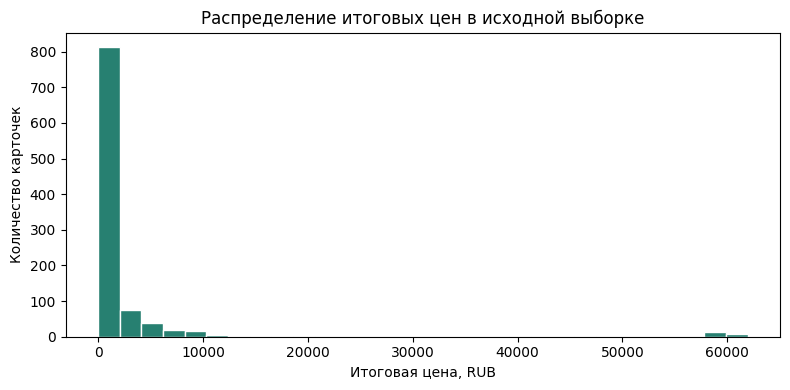

In [5]:
# цель: распределение, при необходимости в числа 0 и 1
print("Тип цели:", raw[TARGET].dtype)
print("Пропусков в цели:", raw[TARGET].isna().sum())
display(raw[TARGET].describe())
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(raw[TARGET].dropna(), bins=30, color=TEAL, edgecolor="white")
ax.set_title("Распределение итоговых цен в исходной выборке")
ax.set_xlabel("Итоговая цена, RUB")
ax.set_ylabel("Количество карточек")
plt.tight_layout()
plt.show()

Исходная таблица содержит 1000 строк и 21 столбец. Каждая строка представляет данные о товаре маркетплейса Wildberries. Для прогнозирования выбрана final_price — итоговая цена товара. Тип данных int64. Есть пропущенные значения в нескольких столбцах. Есть пропуски в rating — 181. Также имеются пропуски в currency, brand, original_product, delivery_options и других столбцах. Некоторые характеристики товаров представлены текстом. Минимальная цена составляет 0Р, максимальная — 61 933Р. Средняя цена равна 2800,85Р, медианная — 607,50Р. Основная масса товаров сосредоточена в области низких цен, присутствуют дорогие товары которые повышают среднее значение.

---
## 2. Дубли  ·  вместе с разделом 3: 15 баллов

**Что сделать.**

* сколько полных дублей: `raw.duplicated().sum()`;
* если в данных есть номер записи (id), то и повторы по нему: `duplicated(subset=["..."])`;
* посмотреть на несколько дублей глазами (`keep=False`) и решить, что это: ошибка выгрузки, одна запись в нескольких местах или разные настоящие строки;
* записать решение в журнал.

Пример: часть 2 практики, разделы 2.1-2.4.

In [6]:
# сколько дублей, какие они
full_duplicates = raw.duplicated().sum()
print("Полных дубликатов:", full_duplicates)
sku_duplicates = raw.duplicated(subset=["sku"]).sum()
print("Повторов SKU:", sku_duplicates)
raw[raw.duplicated(keep=False)].head(10)

Полных дубликатов: 0
Повторов SKU: 0


,url,sku,breadcrumbs,name,rating,review_count,image,brand,initial_price,final_price,membership_price,currency,count_questions,original_product,product_variation,product_variations,product_details,additional_information,delivery_options,images_url,videos_url


In [7]:
# решение: df = ... ; log(...)
df = raw.copy()
log(
    "дубли",
    "Полных дублей: 0, повторов SKU: 0. Строки сохранены.",
    len(df)
)
show_journal()

,решение,строк
загрузка,Исходный CSV Wildberries-dataset-sample из GitHub,1000
дубли,"Полных дублей: 0, повторов SKU: 0. Строки сохр...",1000


Дублей в датасете не обнаружено.

---
## 3. Невозможные значения и скрытые пропуски

**Что сделать.**

* написать функцию `check_rules(d)`, которая возвращает таблицу флагов: минимум 3 правила здравого смысла (отрицательная цена, ноль там, где ноль невозможен, возраст 150 лет);
* посмотреть на нарушителей глазами и решить по каждому правилу: удалить, исправить или оставить;
* найти скрытые пропуски: `value_counts()` по текстовым столбцам, `describe()` по числовым. Ищите `unknown`, `Undefined`, `?`, пробел, `999`, нули там, где их не бывает;
* записать решения в журнал.

Пример: часть 2 практики, разделы 2.5-2.7.

In [8]:
def check_rules(d):
    """Таблица флагов: True там, где строка нарушает правило."""
    return pd.DataFrame({
        "Отрицательная цена": d["final_price"] < 0,
        "Нулевая цена": d["final_price"] == 0,
        "Недопустимый рейтинг": (
            d["rating"].notna()
            & ~d["rating"].between(0, 5)
        ),
        "Отрицательное количество отзывов": (
            d["review_count"] < 0
        )
    })

In [9]:
# сколько нарушений по каждому правилу, нарушители глазами
flags = check_rules(df)
print("Количество нарушений по каждому правилу:")
print(flags.sum())
print("Подозрительные товары:")
display(
    df.loc[
        flags.any(axis=1),
        ["sku", "name", "final_price", "rating", "review_count"]
    ].head(20)
)

Количество нарушений по каждому правилу:
Отрицательная цена                   0
Нулевая цена                        52
Недопустимый рейтинг                 0
Отрицательное количество отзывов     0
dtype: int64
Подозрительные товары:


,sku,name,final_price,rating,review_count
19,13212358,Футболка зеленая лайм однотонная,0,4.9,268869
26,13212362,Футболка оранжевая однотонная,0,4.9,268869
28,13212359,Футболка серый меланж однотонная,0,4.9,268869
39,90369211,Футболка индиго однотонная,0,4.9,268869
43,13212366,Футболка темно-зеленая однотонная,0,4.9,268869
44,26997737,Футболка розовая однотонная,0,4.9,268869
49,13212353,Футболка желтая однотонная,0,4.9,268869
56,39345528,Футболка кофейная меланж однотонная,0,4.9,268869
57,27278438,Футболка антрацитовая однотонная,0,4.9,268869
62,3200490,Жилет утеплённый из овечьей шерсти с капюшоном,0,4.7,113


In [10]:
# скрытые пропуски: value_counts и describe
zero_price = df[df["final_price"] == 0]
print("Товаров с нулевой ценой:", len(zero_price))
display(
    zero_price[
        ["sku", "name", "initial_price",
         "final_price", "membership_price", "rating"]
    ].head(52)
)

Товаров с нулевой ценой: 52


,sku,name,initial_price,final_price,membership_price,rating
19,13212358,Футболка зеленая лайм однотонная,1080,0,428,4.9
26,13212362,Футболка оранжевая однотонная,1080,0,428,4.9
28,13212359,Футболка серый меланж однотонная,1080,0,428,4.9
39,90369211,Футболка индиго однотонная,1080,0,428,4.9
43,13212366,Футболка темно-зеленая однотонная,1080,0,428,4.9
44,26997737,Футболка розовая однотонная,1080,0,428,4.9
49,13212353,Футболка желтая однотонная,1080,0,428,4.9
56,39345528,Футболка кофейная меланж однотонная,494,0,420,4.9
57,27278438,Футболка антрацитовая однотонная,1080,0,428,4.9
62,3200490,Жилет утеплённый из овечьей шерсти с капюшоном,6999,0,2195,4.7


In [11]:
# решения и журнал
zero_price = df[df["final_price"] == 0]
group_1 = zero_price[
    (zero_price["initial_price"] > 0) &
    (zero_price["membership_price"] > 0)
]
group_2 = zero_price[
    (zero_price["initial_price"] == 0) &
    (zero_price["membership_price"] == 0)
]
print("Есть другие цены:", len(group_1))
print("Все три цены нулевые:", len(group_2))
print("Всего проверено:", len(group_1) + len(group_2))


Есть другие цены: 34
Все три цены нулевые: 18
Всего проверено: 52


In [12]:
for col in ["currency", "brand", "original_product"]:
    print("\nСтолбец:", col)
    print(df[col].value_counts(dropna=False).head(10))

print("\nВалюта у товаров с нулевой ценой:")
print(zero_price["currency"].value_counts(dropna=False))


Столбец: currency
currency
RUB    951
NaN     49
Name: count, dtype: int64

Столбец: brand
brand
Лига Диванов    22
UZcotton        18
FankyManky      15
ARUU&HOME       14
ANAM            12
NaN             11
Fox Case        11
Heima           11
PICSIS          10
Andy&Paul        8
Name: count, dtype: int64

Столбец: original_product
original_product
False    877
True      99
NaN       24
Name: count, dtype: int64

Валюта у товаров с нулевой ценой:
currency
RUB    43
NaN     9
Name: count, dtype: int64


In [13]:
markers = ["", "unknown", "undefined", "null",
           "none", "n/a", "na", "?", "-"]
found = False
checked_columns = 0
for col in df.select_dtypes(include="object").columns:
    checked_columns += 1
    values = df[col].dropna().astype(str).str.strip().str.lower()
    suspicious = values.isin(markers)
    if suspicious.any():
        found = True
        print("\nСтолбец:", col)
        print("Подозрительных значений:", suspicious.sum())
        print(values[suspicious].value_counts())
print("\n--- Итог проверки ---")
print("Проверено текстовых столбцов:", checked_columns)
if not found:
    print("Подозрительные текстовые значения из заданного списка НЕ ОБНАРУЖЕНЫ.")
else:
    print("Обнаружены подозрительные текстовые значения. См. результаты выше.")


--- Итог проверки ---
Проверено текстовых столбцов: 14
Подозрительные текстовые значения из заданного списка НЕ ОБНАРУЖЕНЫ.


Проверены четыре правила. отрицательная цена, нулевая цена, рейтинг вне диапазона 0–5 и отрицательное количество отзывов. Обнаружено 52 товара с нулевой итоговой ценой. У 34 товаров другие цены положительные, у 18 — все цены нулевые. Остальные правила нарушений не выявили.
Скрытых текстовых обозначений и пропусков нет. Выявлены обычные пропуски NaN.
Строки пока не удалял и не исправлял.

---
## 4. Пропуски  ·  20 баллов

**Что сделать.**

* для каждого столбца с пропусками сравнить цель у строк с пропуском и без: `df.groupby(df[col].isna())[TARGET].mean()`;
* решить, что значит пропуск: «не знаем» или «нет»;
* заполнить: «нет» по смыслу (0, «нет»), «не знаем» медианой, самым частым или категорией `Unknown`; если пропуск говорит о строке, сначала флаг; если пропусков больше половины, флаг и удалить столбец;
* заполнить таблицу решений ниже и записать решения в журнал.

По желанию, без баллов: проверить способ заполнения на известных значениях, как в разделе 3.4 практики.

Пример: часть 3 практики.

In [14]:
# где пропуски и сколько
missing = df.isna().sum()
missing_table = pd.DataFrame({
    "Пропусков": missing,
    "Доля, %": (df.isna().mean() * 100).round(1)
})
missing_table = missing_table[missing_table["Пропусков"] > 0]
missing_table = missing_table.sort_values(
    "Пропусков", ascending=False
)
display(missing_table)

,Пропусков,"Доля, %"
rating,181,18.1
currency,49,4.9
original_product,24,2.4
delivery_options,12,1.2
brand,11,1.1
videos_url,9,0.9
product_details,2,0.2


In [15]:
# пропуск как информация: цель у строк с пропуском и без
for col in missing_table.index:
    print("\nСтолбец:", col)
    result = df.groupby(
        df[col].isna()
    )["final_price"].agg(["count", "mean", "median"])

    result = result.rename(index={
        False: "Значение есть",
        True: "Пропуск"
    })

    display(result.round(2))



Столбец: rating


,count,mean,median
rating,,,
Значение есть,819,1234.31,530.0
Пропуск,181,9889.22,1428.0



Столбец: currency


,count,mean,median
currency,,,
Значение есть,951,2899.10,610.0
Пропуск,49,894.02,572.0



Столбец: original_product


,count,mean,median
original_product,,,
Значение есть,976,2852.48,607.5
Пропуск,24,701.08,598.0


... (4 outputs left out)


Столбец: videos_url


,count,mean,median
videos_url,,,
Значение есть,991,2822.7,611.0
Пропуск,9,395.0,395.0



Столбец: product_details


,count,mean,median
product_details,,,
Значение есть,998,2801.95,607.5
Пропуск,2,2252.50,2252.5


In [16]:
# заполнение и журнал
df["rating_missing"] = df["rating"].isna().astype(int)
rating_median = df["rating"].median()
df["rating"] = df["rating"].fillna(rating_median)
columns_unknown = [
    "currency",
    "original_product",
    "delivery_options",
    "brand",
    "videos_url",
    "product_details"
]

for col in columns_unknown:
    df[col] = df[col].fillna("Unknown")
print("Медиана рейтинга:", rating_median)
print("Осталось пропусков:", df.isna().sum().sum())
print("Строк после обработки:", len(df))
log(
    "пропуски",
    "Рейтинг заполнен медианой с флагом. "
    "Остальные пропуски заполнены Unknown.",
    len(df)
)


log(
    "невозможные значения",
    "Обнаружено 52 товара с нулевой итоговой ценой. "
    "Строки сохранены до выяснения причины.",
    1000
)
display(show_journal())


Медиана рейтинга: 4.8
Осталось пропусков: 0
Строк после обработки: 1000


,решение,строк
загрузка,Исходный CSV Wildberries-dataset-sample из GitHub,1000
дубли,"Полных дублей: 0, повторов SKU: 0. Строки сохр...",1000
пропуски,Рейтинг заполнен медианой с флагом. Остальные ...,1000
невозможные значения,Обнаружено 52 товара с нулевой итоговой ценой....,1000


| столбец | пропусков | «не знаем» или «нет» | что делаем | почему |
rating      	181	           Не знаем	Медиана 4,8 + флаг
currency	49	Не знаем	Unknown
original_product	24	Не знаем	Unknown
delivery_options	12	Не знаем	Unknown
brand	11	Не знаем	Unknown
videos_url	9	Не знаем	Unknown
product_details	2	Не знаем	Unknown
рейтинг заполнили медианой для сохранения числового признака, а флагом отметили исходные пропуски. Остальные значения оставили неизвестными, так как отсутствие данных не доказывает отсутствие соответствующего свойства товара.

---
## 5. Типы и даты  ·  вместе с разделом 6: 15 баллов

**Что сделать.**

* числа, записанные текстом, превратить в числа: `pd.to_numeric(s, errors="coerce")`, и посмотреть, что попало в пропуски;
* текст с единицами («76%», «SR 1,385», «1800-2200») разобрать: `str.replace`, `str.extract`;
* даты превратить в даты: `pd.to_datetime`, и достать из них признаки: месяц, день недели, час, разницу дат;
* показать `dtypes` после исправлений.

Если в ваших данных нет ни дат, ни чисел текстом, напишите это в выводе: так тоже бывает.

Пример: часть 4 практики, разделы 4.1-4.3.

In [17]:
# числа текстом
print("Типы данных:")
display(df.dtypes.to_frame("Тип данных"))
numeric_cols = [
    "rating",
    "review_count",
    "initial_price",
    "final_price",
    "membership_price",
    "count_questions"
]
print("\nПроверка числовых столбцов:")
for col in numeric_cols:
    if pd.api.types.is_numeric_dtype(df[col]):
        print(col, "- числовой тип, всё правильно")
    else:
        print(col, "- ВНИМАНИЕ: требуется преобразование")

Типы данных:


,Тип данных
url,object
sku,int64
breadcrumbs,object
name,object
rating,float64
review_count,int64
image,object
brand,object
initial_price,int64
final_price,int64



Проверка числовых столбцов:
rating - числовой тип, всё правильно
review_count - числовой тип, всё правильно
initial_price - числовой тип, всё правильно
final_price - числовой тип, всё правильно
membership_price - числовой тип, всё правильно
count_questions - числовой тип, всё правильно


In [18]:
# даты
date_columns = [
    col for col in df.columns
    if "date" in col.lower() or "time" in col.lower()
]

print("Найдено столбцов с датами:", len(date_columns))

if date_columns:
    print("Возможные столбцы с датами:", date_columns)
else:
    print("Столбцы с датами не обнаружены.")
display(df.dtypes.to_frame("Тип данных"))


Найдено столбцов с датами: 0
Столбцы с датами не обнаружены.


,Тип данных
url,object
sku,int64
breadcrumbs,object
name,object
rating,float64
review_count,int64
image,object
brand,object
initial_price,int64
final_price,int64


Шесть основных числовых столбцов имеют корректные типы данных, преобразование не требуется. Столбцы с датами отсутствуют, поэтому обработка дат не выполнялась.

---
## 6. Выбросы

**Что сделать.**

* для главных числовых столбцов найти кандидатов в выбросы: граница IQR или процентили (`quantile(0.999)`);
* по каждому решить: ошибка (удалить или исправить) или редкость (оставить, обрезать `clip`, сжать `np.log1p`);
* для длинного хвоста показать гистограммы до и после логарифма;
* записать решения в журнал.

Пример: часть 4 практики, разделы 4.4-4.6.

In [19]:
# кандидаты в выбросы
columns = [
    "initial_price",
    "final_price",
    "membership_price",
    "review_count"
]
for col in columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    print("\nСтолбец:", col)
    print("Нижняя граница:", round(lower, 2))
    print("Верхняя граница:", round(upper, 2))
    print("Найдено выбросов:", len(outliers))
    print("Максимальное значение:", df[col].max())

for col in columns:
    print("\nСтолбец:", col)
    print("ТОП-5 максимальных значений:")

    display(
        df.nlargest(5, col)[
            ["sku", "name", col]
        ]
    )

print("Товары с самой высокой ценой по программе лояльности:")

display(
    df.nlargest(5, "membership_price")[
        ["sku", "name", "initial_price",
         "final_price", "membership_price"]
    ]
)

max_reviews = df["review_count"].max()
popular = df[df["review_count"] == max_reviews]

print("\nМаксимальное количество отзывов:", max_reviews)
print("Товаров с таким количеством отзывов:", len(popular))
print("Уникальных SKU:", popular["sku"].nunique())

display(
    popular[["sku", "name", "review_count"]]
)



Столбец: initial_price
Нижняя граница: -5318.75
Верхняя граница: 11321.25
Найдено выбросов: 98
Максимальное значение: 117298

Столбец: final_price
Нижняя граница: -1516.5
Верхняя граница: 3497.5
Найдено выбросов: 124
Максимальное значение: 61933

Столбец: membership_price
Нижняя граница: -1305.5
Верхняя граница: 3150.5
Найдено выбросов: 109
Максимальное значение: 45621

Столбец: review_count
Нижняя граница: -406.0
Верхняя граница: 682.0
Найдено выбросов: 155
Максимальное значение: 268869

Столбец: initial_price
ТОП-5 максимальных значений:


,sku,name,initial_price
109,218762137,Угловой диван Перри НПБ правый угол,117298
580,218762131,Угловой диван Перри НПБ правый угол,117298
584,218762139,Угловой диван Перри НПБ правый угол,117298
685,218762138,Угловой диван Перри НПБ правый угол,117298
802,218762135,Угловой диван Перри НПБ правый угол,117298



Столбец: final_price
ТОП-5 максимальных значений:


,sku,name,final_price
109,218762137,Угловой диван Перри НПБ правый угол,61933
580,218762131,Угловой диван Перри НПБ правый угол,61933
584,218762139,Угловой диван Перри НПБ правый угол,61933
685,218762138,Угловой диван Перри НПБ правый угол,61933
802,218762135,Угловой диван Перри НПБ правый угол,61933



Столбец: membership_price
ТОП-5 максимальных значений:


,sku,name,membership_price
914,202493170,Матрас детский FUNNY ECO беспружинный в кроват...,45621
100,197054274,МФУ лазерное Color LaserJet Pro M182n А4 цветн...,38461
387,143019713,Электропастух Элеток веревка 1000м с изолятора...,18570
493,160110429,Комплект прокладок двигателя Yamaha 500-340,16762
152,143019721,"Электропастух для КРС коров, 25 Га/2000м, для ...",14837


... (2 outputs left out)

Товары с самой высокой ценой по программе лояльности:


,sku,name,initial_price,final_price,membership_price
914,202493170,Матрас детский FUNNY ECO беспружинный в кроват...,55332,47032,45621
100,197054274,МФУ лазерное Color LaserJet Pro M182n А4 цветн...,52716,40064,38461
387,143019713,Электропастух Элеток веревка 1000м с изолятора...,26808,19344,18570
493,160110429,Комплект прокладок двигателя Yamaha 500-340,20787,17461,16762
152,143019721,"Электропастух для КРС коров, 25 Га/2000м, для ...",21684,15456,14837



Максимальное количество отзывов: 268869
Товаров с таким количеством отзывов: 18
Уникальных SKU: 18


,sku,name,review_count
13,13212350,Футболка голубая однотонная,268869
19,13212358,Футболка зеленая лайм однотонная,268869
20,26990809,Футболка оливковая однотонная,268869
21,12801487,Футболка фиолетовая слива однотонная,268869
26,13212362,Футболка оранжевая однотонная,268869
27,13212356,Футболка красная однотонная,268869
28,13212359,Футболка серый меланж однотонная,268869
30,13212354,Футболка зеленая однотонная,268869
38,13212363,Футболка персиковая однотонная,268869
39,90369211,Футболка индиго однотонная,268869



Исследуем столбец: final_price


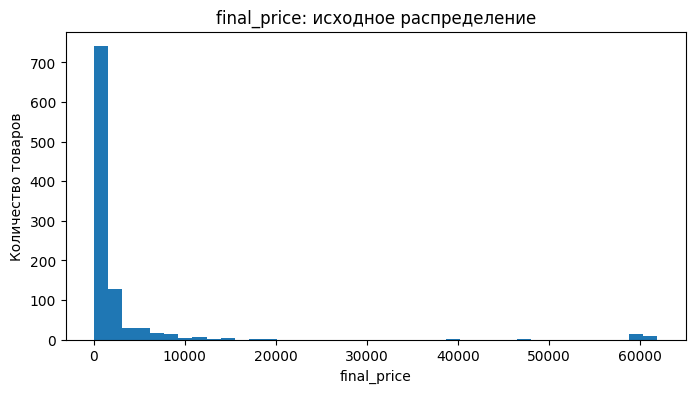

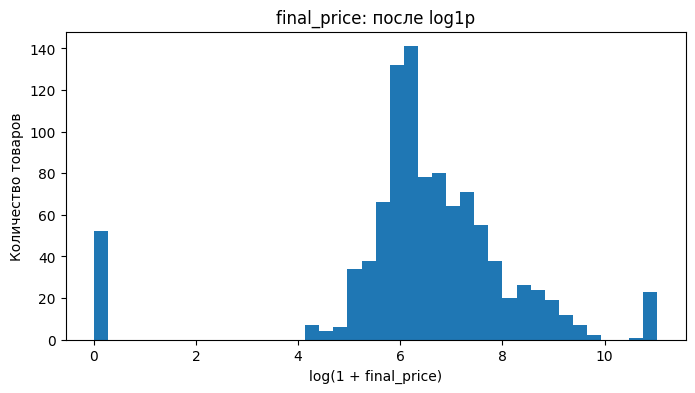


Исследуем столбец: review_count


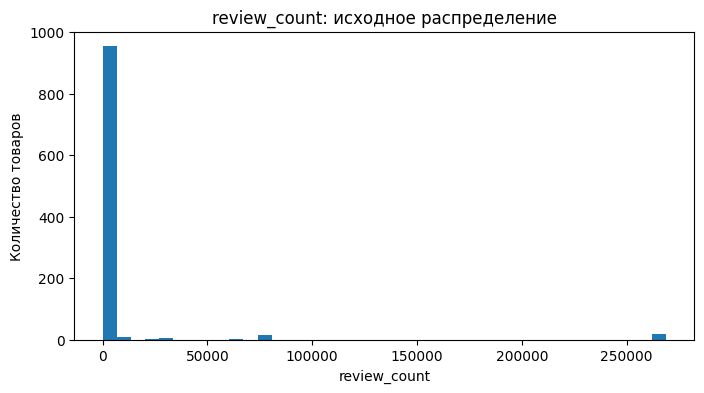

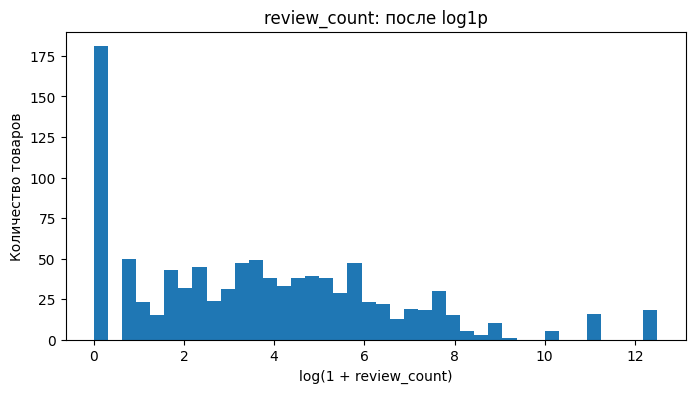

,решение,строк
загрузка,Исходный CSV Wildberries-dataset-sample из GitHub,1000
дубли,"Полных дублей: 0, повторов SKU: 0. Строки сохр...",1000
пропуски,Рейтинг заполнен медианой с флагом. Остальные ...,1000
невозможные значения,Обнаружено 52 товара с нулевой итоговой ценой....,1000
выбросы,"IQR: initial_price — 98, final_price — 124, me...",1000


Строк после анализа выбросов: 1000


In [20]:
# решения: удалить, обрезать, логарифм
columns_log = ["final_price", "review_count"]

for col in columns_log:
    print("\nИсследуем столбец:", col)

    plt.figure(figsize=(8, 4))
    plt.hist(df[col], bins=40)
    plt.title(f"{col}: исходное распределение")
    plt.xlabel(col)
    plt.ylabel("Количество товаров")
    plt.show()

    plt.figure(figsize=(8, 4))
    plt.hist(np.log1p(df[col]), bins=40)
    plt.title(f"{col}: после log1p")
    plt.xlabel(f"log(1 + {col})")
    plt.ylabel("Количество товаров")
    plt.show()

log(
    "выбросы",
    "IQR: initial_price — 98, final_price — 124, "
    "membership_price — 109, review_count — 155. "
    "Проверенные максимумы могут быть реальными. "
    "Выбросы сохранены, clip и удаление не применялись. "
    "Для final_price и review_count исследован log1p.",
    len(df)
)

display(show_journal())

print("Строк после анализа выбросов:", len(df))



Методом IQR обнаружены выбросы initial_price 98, final_price 124, membership_price 109, review_count 155.
Высокие цены встречаются у дорогих товаров (диваны, матрасы, техника). Проверка Wildberries подтвердила, что 18 футболок с одинаковыми 268 869 отзывами принадлежат одной объединённой карточке. Подтверждённых ошибок среди проверенных выбросов не найдено. Значения сохранены. Логарифмирование позволило лучше исследовать распределения. Все 1000 строк оставлены.

---
## 7. EDA: пять графиков  ·  20 баллов

**Что сделать.** Минимум 5 графиков. У каждого заголовок-вывод (не «lead_time и is_canceled», а «Чем раньше бронь, тем чаще отмена»), подписи осей с единицами и 1-3 предложения под графиком.

| график | на какой вопрос отвечает |
|---|---|
| распределение цели | какая доля классов или как распределено число |
| цель по 3-4 сильным признакам | что сильнее всего связано с целью |
| цель по времени или по группам | меняется ли картина по сезонам, городам, категориям |
| находка | что удивило: парадокс или подозрительно идеальный признак |

`target_plot(df, группы, TARGET, "заголовок-вывод", "подпись оси x")` рисует цель по группам. Числовой признак сначала разбейте на интервалы: `pd.cut(df["столбец"], [границы])`. Для двух числовых столбцов подойдёт `plt.scatter`.

Пример: часть 6 практики.

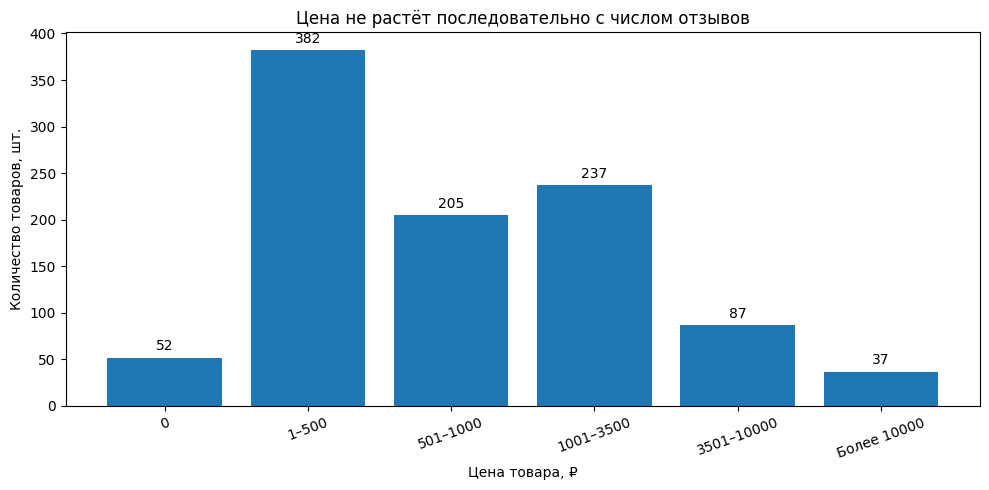

,Количество товаров
final_price,
0,52
1–500,382
501–1000,205
1001–3500,237
3501–10000,87
Более 10000,37


In [21]:
# график 1
price_groups = pd.cut(
    df["final_price"],
    bins=[-0.5, 0.5, 500, 1000, 3500, 10000, float("inf")],
    labels=["0", "1–500", "501–1000",
            "1001–3500", "3501–10000", "Более 10000"]
)
price_counts = price_groups.value_counts(sort=False)
fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    price_counts.index.astype(str),
    price_counts.values
)
ax.bar_label(bars, padding=3)
ax.set_title("Цена не растёт последовательно с числом отзывов")
ax.set_xlabel("Цена товара, ₽")
ax.set_ylabel("Количество товаров, шт.")

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()
display(price_counts.to_frame("Количество товаров"))



Наибольшее количество товаров находится в диапазоне 1–500Р. С ростом цены количество товаров в целом сокращается. Нужно проверить 52 товара с нулевой ценой.

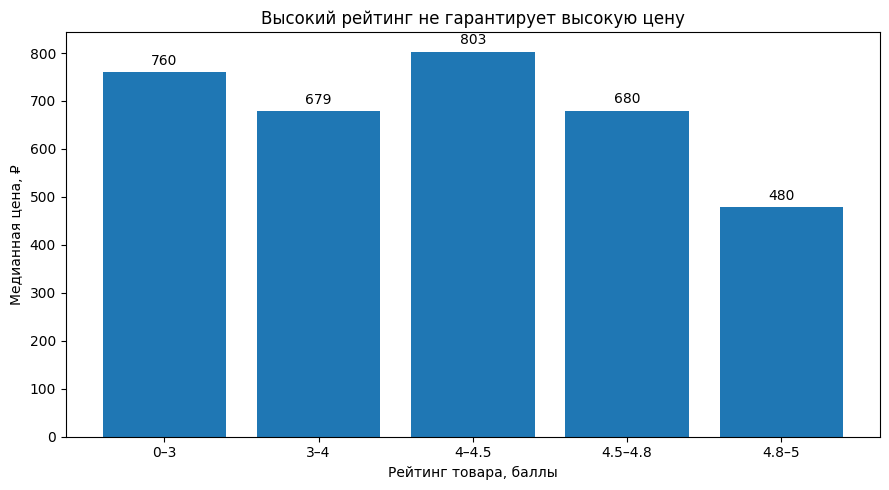

,median,size
rating_group,,
0–3,760.0,8
3–4,679.0,35
4–4.5,803.0,101
4.5–4.8,680.0,287
4.8–5,479.5,296


In [22]:
# график 2
rated = df[
    (df["rating_missing"] == 0) &
    (df["final_price"] > 0) &
    (df["currency"] == "RUB")
].copy()
rated["rating_group"] = pd.cut(
    rated["rating"],
    bins=[-0.01, 3, 4, 4.5, 4.8, 5],
    labels=["0–3", "3–4", "4–4.5", "4.5–4.8", "4.8–5"]
)
stats = rated.groupby("rating_group", observed=True)[
    "final_price"
].agg(["median", "size"])
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    stats.index.astype(str),
    stats["median"]
)
ax.bar_label(bars, fmt="%.0f", padding=3)
ax.set_title("Высокий рейтинг не гарантирует высокую цену")
ax.set_xlabel("Рейтинг товара, баллы")
ax.set_ylabel("Медианная цена, ₽")
plt.tight_layout()
plt.show()
display(stats)

Прямого роста медианной цены с увеличением рейтинга не обнаружено. Максимальная медианная цена — 803Р при рейтинге 4–4,5, минимальная 480Р при рейтинге 4,8–5. Высокий рейтинг не обязательно означает высокую стоимость товара.

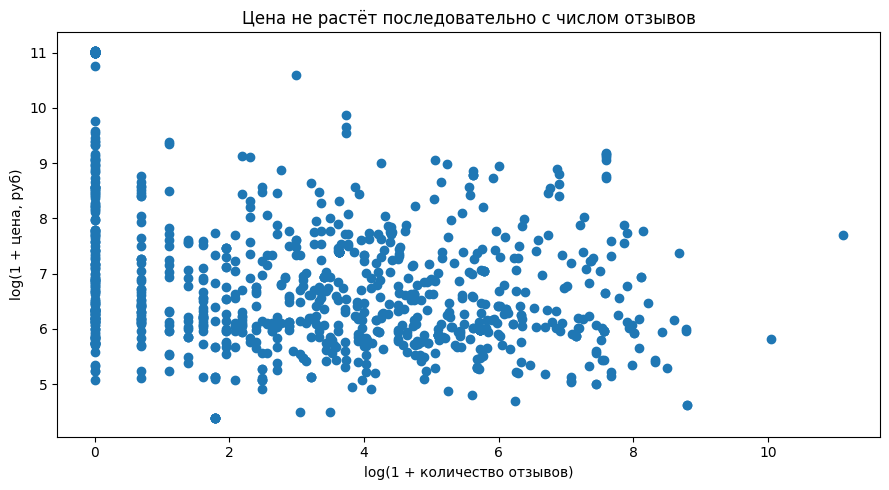

Количество товаров на графике: 908


In [23]:
# график 3
data = df[
    (df["final_price"] > 0) &
    (df["currency"] == "RUB")
].copy()
x = np.log1p(data["review_count"])
y = np.log1p(data["final_price"])
fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(x, y)
ax.set_title("Цена не растёт последовательно с числом отзывов")
ax.set_xlabel("log(1 + количество отзывов)")
ax.set_ylabel("log(1 + цена, руб)")
plt.tight_layout()
plt.show()
print("Количество товаров на графике:", len(data))


На графике не наблюдается выраженного роста цены с увеличением количества отзывов. Среди товаров с небольшим числом отзывов встречаются как дешёвые, так и дорогие позиции.

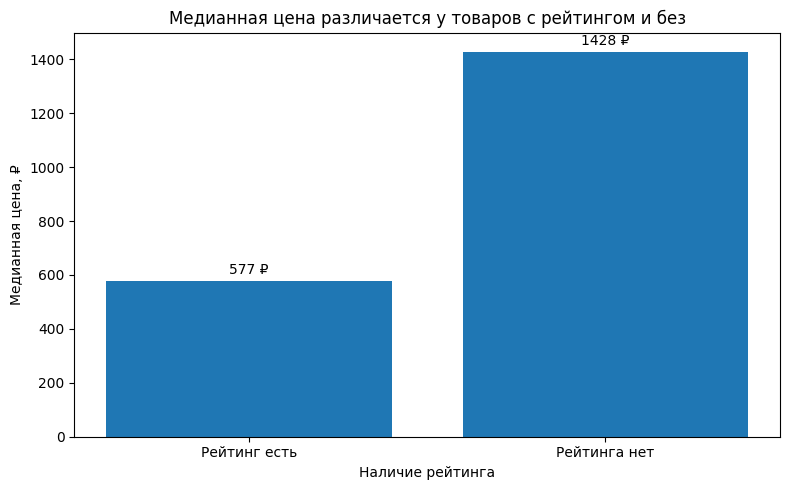

,median,count
rating_missing,,
0,577.0,727
1,1428.0,181


In [24]:
# график 4
data = df[
    (df["final_price"] > 0) &
    (df["currency"] == "RUB")
].copy()
stats = data.groupby("rating_missing")["final_price"].agg(
    ["median", "count"]
)
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    ["Рейтинг есть", "Рейтинга нет"],
    stats.loc[[0, 1], "median"]
)
ax.bar_label(bars, fmt="%.0f ₽", padding=3)
ax.set_title("Медианная цена различается у товаров с рейтингом и без")
ax.set_xlabel("Наличие рейтинга")
ax.set_ylabel("Медианная цена, ₽")
plt.tight_layout()
plt.show()
display(stats)

Товары без рейтинга имеют медианную цену 1428 ₽, что примерно в 2,5 раза выше, чем у товаров с рейтингом (577 руб). Следовательно, отсутствие рейтинга может содержать полезную информацию для прогнозирования цены.

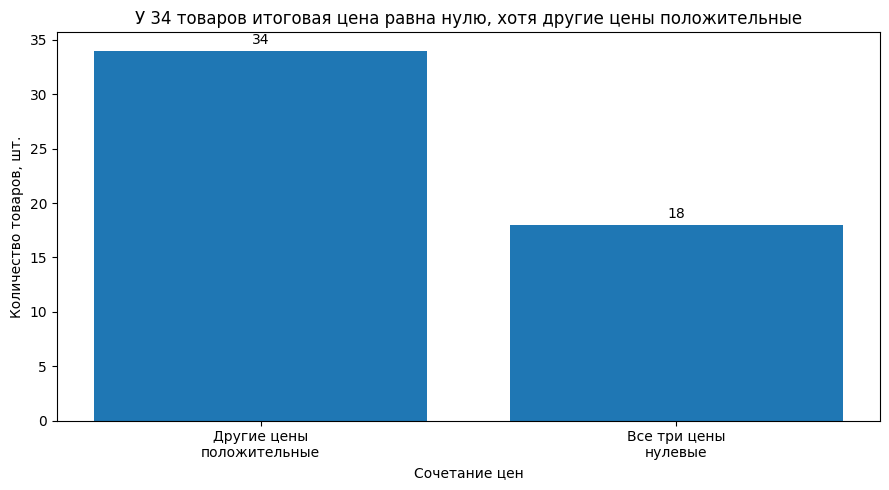

Всего товаров с нулевой итоговой ценой: 52
Другие цены положительные: 34
Все три цены нулевые: 18
Другие сочетания: 0


In [25]:
# график 5
zero = df[df["final_price"] == 0]
positive = (
    (zero["initial_price"] > 0) &
    (zero["membership_price"] > 0)
).sum()
all_zero = (
    (zero["initial_price"] == 0) &
    (zero["membership_price"] == 0)
).sum()
other = len(zero) - positive - all_zero

groups = [
    "Другие цены\nположительные",
    "Все три цены\nнулевые"
]
counts = [positive, all_zero]
if other > 0:
    groups.append("Другие сочетания")
    counts.append(other)
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(groups, counts)
ax.bar_label(bars, padding=3)

ax.set_title(
    f"У {positive} товаров итоговая цена равна нулю, "
    "хотя другие цены положительные"
)
ax.set_xlabel("Сочетание цен")
ax.set_ylabel("Количество товаров, шт.")
plt.tight_layout()
plt.show()
print("Всего товаров с нулевой итоговой ценой:", len(zero))
print("Другие цены положительные:", positive)
print("Все три цены нулевые:", all_zero)
print("Другие сочетания:", other)


Обнаружены 52 товара с нулевой итоговой ценой. У 34 из них остальные цены положительные, у 18 — все три цены нулевые. Причина таких значений не установлена

Среди товаров с положительной ценой 86,9% стоят не более 3500 ₽.
Прямого роста цены с увеличением рейтинга не обнаружено: медианная цена составляет 803 ₽ для рейтинга 4–4,5 и 480 ₽ для рейтинга 4,8–5.
Выраженной зависимости цены от количества отзывов визуально не выявлено.
Товары без рейтинга имеют медианную цену 1428 ₽ против 577 ₽ у товаров с рейтингом.
Обнаружены 52 товара с нулевой итоговой ценой. У 34 из них другие цены положительные, что требует дополнительной проверки.

---
## 8. Функция clean, сторожа и журнал  ·  10 баллов

**Что сделать.**

* собрать все решения разделов 2-6 в одну функцию `clean(raw_table)`: на входе сырая таблица, на выходе чистая;
* проверить, что `clean(raw)` даёт ту же таблицу, что пошаговая очистка;
* сторожа: `assert` на главные правила, например «нет пропусков», «нет невозможных значений»;
* показать журнал: `show_journal()`;
* сохранить чистые данные: `clean_df.to_csv("data/<имя>_clean.csv", index=False)`.

Пример: часть 9 практики, разделы 9.1-9.4.

In [26]:

def clean(raw_table):
    """Сырая таблица на входе, очищенная на выходе."""
    d = raw_table.copy()
    d["rating_missing"] = d["rating"].isna().astype(int)
    rating_median = d["rating"].median()
    d["rating"] = d["rating"].fillna(rating_median)
    columns_unknown = [
        "currency",
        "original_product",
        "delivery_options",
        "brand",
        "videos_url",
        "product_details"
    ]

    for col in columns_unknown:
        d[col] = d[col].fillna("Unknown")
    return d


In [27]:
# clean_df = clean(raw); сравнение с пошаговой очисткой; сторожа assert
clean_df = clean(raw)
assert clean_df.equals(df), "Таблицы не совпадают!"
print("Проверка 1: таблицы совпадают.")
assert len(clean_df) == 1000
print("Проверка 2: сохранены все 1000 строк.")
assert clean_df.isna().sum().sum() == 0
print("Проверка 3: пропусков нет.")
assert clean_df["sku"].is_unique
print("Проверка 4: SKU не повторяются.")
assert (clean_df["final_price"] >= 0).all()
assert clean_df["rating"].between(0, 5).all()
assert (clean_df["review_count"] >= 0).all()
print("Проверка 5: основные числовые правила соблюдены.")
print("\nВсе проверки пройдены!")
print("Размер очищенной таблицы:", clean_df.shape)

Проверка 1: таблицы совпадают.
Проверка 2: сохранены все 1000 строк.
Проверка 3: пропусков нет.
Проверка 4: SKU не повторяются.
Проверка 5: основные числовые правила соблюдены.

Все проверки пройдены!
Размер очищенной таблицы: (1000, 22)


In [28]:
# show_journal()
display(show_journal())

,решение,строк
загрузка,Исходный CSV Wildberries-dataset-sample из GitHub,1000
дубли,"Полных дублей: 0, повторов SKU: 0. Строки сохр...",1000
пропуски,Рейтинг заполнен медианой с флагом. Остальные ...,1000
невозможные значения,Обнаружено 52 товара с нулевой итоговой ценой....,1000
выбросы,"IQR: initial_price — 98, final_price — 124, me...",1000


In [29]:
from pathlib import Path
Path("data").mkdir(exist_ok=True)
clean_df.to_csv(
    "data/wildberries_clean.csv",
    index=False
)
file_path = Path("data/wildberries_clean.csv")
assert file_path.exists(), "Файл не найден!"
print("Файл сохранён:", file_path)
print("Строк:", len(clean_df))
print("Столбцов:", len(clean_df.columns))

Файл сохранён: data/wildberries_clean.csv
Строк: 1000
Столбцов: 22


---
## 9. Самопроверка и репозиторий  ·  10 баллов

**Самопроверка.** Уберите `#` и запустите. Всё должно быть `OK`, а если где-то `НЕТ` по делу (например, дубли появились после обрезки выбросов, как в части 9 практики), объясните это в выводе.

In [30]:
selfcheck(raw, clean_df, TARGET)

OK   цель есть в чистой таблице
OK   цель без пропусков
OK   цель числом: класс 0 и 1 или число
OK   в чистой таблице нет пропусков
OK   полных дублей нет (если есть, объясните в выводе)
OK   осталось больше половины строк
OK   в журнале минимум 5 решений
строк: было 1000, стало 1000; столбцов: было 21, стало 22


**Репозиторий.**

1. github.com, справа вверху «+», затем «New repository». Имя, например, `midterm-telco`, видимость **Public**, галочку README не ставить.
2. «Среда выполнения», затем «Перезапустить сеанс и выполнить все»: тетрадь проходит без ошибок. Сохраните её.
3. Скачайте тетрадь: «Файл», затем «Скачать», затем «Скачать .ipynb», имя `project.ipynb`. Скачайте чистый CSV из папки `data` на панели файлов слева.
4. На странице репозитория ссылка «uploading an existing file», перетащите `project.ipynb` и папку `data`, «Commit changes» с подписью «этап 1».
5. Откройте ссылку в режиме инкогнито: тетрадь открывается, графики видны. Сдайте ссылку в LMS.

README на этапе 1 можно сделать черновым: название проекта и одна строка о задаче. Полный README это этап 2.

Пример: часть 9 практики, разделы 9.5-9.6.

---
# Этап 2. Мидтерм, домашка занятия 12

Эти разделы заполняются после занятия 12, в этой же тетради и в том же репозитории. Здесь коротко, что в них будет. Подробности и баллы в ТЗ, примеры в частях 5, 7, 8 и 9 тетради практики занятия 11. Инструменты занятия 12 можно и нужно использовать.

## 10. Новые признаки

Минимум 3 признака из смысла задачи: суммы, доли, флаги, части дат. У каждого одно предложение «зачем». Пример: часть 5, раздел 5.1.

In [31]:
# этап 2

## 11. Категории

Редкие значения в `Other`, флаги через `get_dummies`. Итог: таблица признаков `X` только из чисел, без пропусков. Пример: часть 5, разделы 5.2-5.5.

In [32]:
# этап 2

## 12. Утечка

Таблица «столбец, когда становится известен, берём или нет» для всех подозрительных столбцов. Проверка моделью хотя бы одного подозреваемого: насколько он поднимает качество. Пример: часть 7.

In [33]:
# этап 2

## 13. Baseline

Train и test, пустышка, простая модель на 3-5 признаках, полная модель в `Pipeline`, кросс-валидация на train, test один раз в конце, график-лестница и вывод «модель лучше пустышки на ...». Пример: часть 8.

In [34]:
# этап 2

## 14. Выводы

3-5 пунктов: что узнали о данных, что сработало, что бы сделали дальше.

## 15. README

По шаблону из ТЗ. Журнал и результаты удобно собрать из переменных тетради. Пример: часть 9, раздел 9.4.

In [35]:
# этап 2

## 16. Финальная проверка

`requirements.txt`, «Перезапустить сеанс и выполнить все» без ошибок, тетрадь сохранена с выводами, ссылка открывается в режиме инкогнито. Чек-лист в ТЗ.